# SMS spam classifier (NLP)
TF-IDF features (word n-grams + character n-grams) with Naive Bayes, logistic regression and a linear SVM, evaluated by stratified cross-validation. The best pipeline is saved for reuse.
Data: UCI SMS Spam Collection (5,572 messages).

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
d = pd.read_csv("data/sms_spam.csv", encoding="latin-1").iloc[:, :2]; d.columns = ["label", "text"]
d["spam"] = (d.label == "spam").astype(int)
print(f"{len(d):,} messages, {d.spam.mean():.1%} spam")
d.groupby("label").text.apply(lambda s: s.str.len().median()).rename("median length")

5,572 messages, 13.4% spam


label
ham      52.0
spam    149.0
Name: median length, dtype: float64

In [2]:
feats = lambda: make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                           TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True))
models = {"Naive Bayes": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), MultinomialNB(alpha=0.1)),
          "Logistic regression": make_pipeline(feats(), LogisticRegression(C=20, max_iter=3000, class_weight="balanced")),
          "Linear SVM": make_pipeline(feats(), LinearSVC(C=1.0, class_weight="balanced"))}
X_tr, X_te, y_tr, y_te = train_test_split(d.text, d.spam, test_size=0.2, stratify=d.spam, random_state=1)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
res = {k: {m: v.mean() for m, v in cross_validate(mdl, X_tr, y_tr, cv=cv, scoring=["precision", "recall", "f1"]).items() if m.startswith("test")}
       for k, mdl in models.items()}
pd.DataFrame(res).T.rename(columns=lambda c: c.replace("test_", "CV ")).round(3)

,CV precision,CV recall,CV f1
Naive Bayes,0.994,0.905,0.947
Logistic regression,0.979,0.943,0.961
Linear SVM,0.989,0.935,0.961


              precision    recall  f1-score   support

         ham      0.990     0.999     0.994       966
        spam      0.993     0.933     0.962       149

    accuracy                          0.990      1115
   macro avg      0.991     0.966     0.978      1115
weighted avg      0.990     0.990     0.990      1115



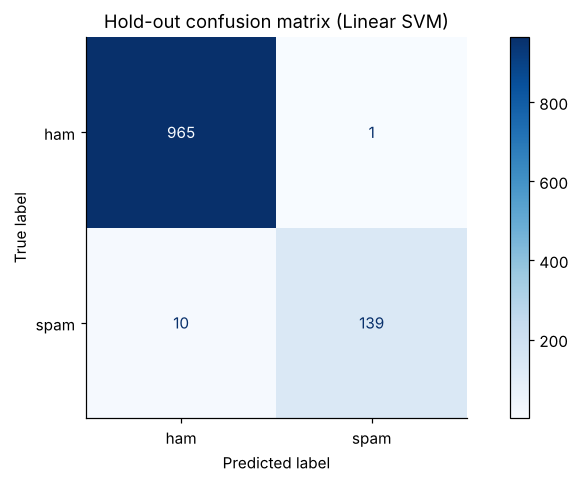

In [3]:
best = models["Linear SVM"].fit(X_tr, y_tr)
print(classification_report(y_te, best.predict(X_te), target_names=["ham", "spam"], digits=3))
ConfusionMatrixDisplay.from_estimator(best, X_te, y_te, display_labels=["ham", "spam"], cmap="Blues")
plt.title("Hold-out confusion matrix (Linear SVM)"); plt.grid(False); plt.savefig(IMG / "confusion.png", bbox_inches="tight"); plt.show()

In [4]:
lr = models["Logistic regression"].fit(X_tr, y_tr)
names = np.r_[lr[0].transformer_list[0][1].get_feature_names_out(), lr[0].transformer_list[1][1].get_feature_names_out()]
coef = pd.Series(lr[-1].coef_[0], index=names)
word = coef[[(" " not in n.strip() or len(n.split()) <= 2) and not n.startswith(" ") and len(n) > 2 for n in coef.index]]
print("Strongest spam signals:", ", ".join(word.sort_values().tail(15).index[::-1]))
pathlib.Path("model").mkdir(exist_ok=True); joblib.dump(best, "model/spam_svm.joblib")
tests = ["Congratulations! You've won a $1000 gift card. Call now to claim", "Are we still meeting for lunch tomorrow?"]
for t, p in zip(tests, best.predict(tests)): print(f"{'SPAM' if p else 'ham '} | {t}")

Strongest spam signals: txt, call, free, text, xt , www, won, 00 , txt, stop, claim, 150p, 087, now, com
SPAM | Congratulations! You've won a $1000 gift card. Call now to claim
ham  | Are we still meeting for lunch tomorrow?


**Result:** character n-grams make the classifier robust to obfuscated spam ("FR33", "txt"). The linear SVM reaches high precision, which matters because filtering a genuine message costs more than letting one spam through. The saved pipeline (`model/spam_svm.joblib`) can be loaded with `joblib.load` and called on raw text.